# Más allá: las reconciliaciones contra motores de referencia que existen hoy

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los cuadernos 03, 05 y 06 de este tema (la inmersión, la calibración y las cotas de bajo incumplimiento)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este cuaderno puedes:

- listar las reconciliaciones del motor contra referencias independientes que existen hoy para los casos de calificaciones y calibración: cinco artículos impresos, y dos recálculos independientes de los valores p de las pruebas de Jeffreys y binomial;
- leer, para cada fuente, cuántos números impresos se recalcularon, cuántos coinciden en el dígito impreso y la mayor diferencia, desde los artefactos versionados;
- verificar los valores p del motor en una grilla contra una cuadratura de la densidad Beta y una suma exacta de los términos binomiales, y decir por qué una comparación con las llamadas a SciPy que el propio motor hace no probaría nada;
- decir qué diferencias registran los artefactos y con qué explicación, y qué reconciliaciones de la afirmación pertenecen a otro cuaderno o no se vuelven a correr aquí;
- enunciar la afirmación BS-2 del producto, la evidencia que la respalda y sus límites.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from fractions import Fraction
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation import validation
from scipy import integrate

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cuatro archivos versionados, todos producidos por el pipeline desde artículos que son fuentes de solo derivados (los artefactos llevan los números impresos y el recálculo, nunca las tablas de conteos de los artículos):

- `data/derived/C04/published.json`: tres artículos recalculados junto a sus impresos. Israel, Rosenthal y Wei (2001): nueve distancias L1. Schuermann y Hanson (2004), Tabla 5: los intervalos de Wald y de Agresti-Coull para BB en 2002. Engelmann (2024): el portafolio TTC y cuatro portafolios iniciales.
- `data/derived/C05/sp-2010.json` y `sp-2011.json`: Tasche (2013), Tablas 5 a 9 (`outputs.golden`): la curva suavizada, el perfil implicado, las curvas de pronóstico de cuatro enfoques, los valores p, las PD del caso 3 y las razones de verosimilitud.
- `data/derived/C05/ldp-published.json`: Pluto y Tasche (2005), Tablas 1 a 14, 204 celdas (`outputs.golden.cells`).

Las pruebas de reconciliación del propio repositorio (`tests/test_c04_parity.py`, `tests/test_c04_published.py`, `tests/test_c05.py`) corren en la batería de pruebas del producto, no aquí. La celda siguiente carga los archivos.

In [2]:
# Cargar los cuatro artefactos (el cuaderno está tres carpetas bajo la raíz del repositorio) e imprimir las versiones del motor
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
load = lambda case, name: json.loads((DERIVED / case / name).read_text(encoding="utf-8"))
published, ldp = load("C04", "published.json"), load("C05", "ldp-published.json")
tasche = {2010: load("C05", "sp-2010.json"), 2011: load("C05", "sp-2011.json")}
for label, doc in (("published", published), ("ldp-published", ldp), ("sp-2010", tasche[2010]), ("sp-2011", tasche[2011])):
    print(f"{label:14s} calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

published      calculado con riskvalidation 0.4.3 | instalado 0.9.0
ldp-published  calculado con riskvalidation 0.4.3 | instalado 0.9.0
sp-2010        calculado con riskvalidation 0.4.3 | instalado 0.9.0
sp-2011        calculado con riskvalidation 0.4.3 | instalado 0.9.0


## Método

### Paso 1: qué se reconcilia, fuente por fuente

Una reconciliación recalcula un número publicado con el motor y pone los dos lado a lado. Cada artefacto registra, para cada número impreso, lo impreso, el recálculo y la diferencia. La celda siguiente los cuenta por fuente: el número de números impresos comparados, cuántos reproduce el motor hasta el dígito impreso, y la mayor diferencia en la unidad de lo impreso. Una diferencia es cero cuando el valor recalculado, redondeado a la precisión impresa, iguala lo impreso; las reglas de cada tabla (por ejemplo "a media unidad del último dígito impreso") son las propias de los artefactos y se listan en las notas de los resultados de este cuaderno.

In [3]:
# Contar los números impresos recalculados por fuente: cuántos, cuántos coinciden en el dígito impreso y la mayor diferencia
rows = []                                               # (fuente, números comparados, coinciden, mayor diferencia, unidad)
out_pub = published["outputs"]

irw = out_pub["irw"]["rows"]
rows.append(("Israel et al. (2001), distancias L1", len(irw), sum(r["agrees"] for r in irw), max(abs(r["printed"] - r["recomputed"]) for r in irw), "distancia L1"))
sr = out_pub["sr190"]["rows"]
cells = [(p, r_) for row in sr for p, r_ in zip(row["printed"], row["recomputed"])]
rows.append(("Schuermann y Hanson (2004), Tabla 5", len(cells), sum(row["agrees"] for row in sr) * 3, 1e4 * max(abs(p - r_) for p, r_ in cells), "puntos base"))
eng = out_pub["engelmann"]
checks = list(zip(eng["w_ttc"]["printed"], eng["w_ttc"]["recomputed"], eng["w_ttc"]["decimals"])) + [(eng["ttc_pd"]["printed"], eng["ttc_pd"]["recomputed"], eng["ttc_pd"]["decimals"])]
checks += [(q["pd0"]["printed"], q["pd0"]["recomputed"], q["pd0"]["decimals"]) for q in eng["portfolios"] if q["pd0"]["check"] == "printed digits"]
agree = sum(abs(r_ - p) <= 0.5 * 10.0 ** -d + 1e-9 for p, r_, d in checks)
rows.append(("Engelmann (2024), portafolio TTC y PD", len(checks), int(agree), max(abs(r_ - p) for p, r_, _ in checks), "probabilidad"))

g = tasche[2010]["outputs"]["golden"]
for key, label in (("table5", "Tabla 5, curva de 2009"), ("table6", "Tabla 6, perfil implicado")):
    gaps = [abs(c["gap"]) for c in g[key]]
    rows.append((f"Tasche (2013), {label}", len(gaps), sum(x == 0 for x in gaps), max(gaps), "puntos porcentuales"))
for year in (2010, 2011):
    gaps = [abs(c["gap"]) for cs in tasche[year]["outputs"]["golden"]["table7"].values() for c in cs]
    rows.append((f"Tasche (2013), Tabla 7, curvas {year}", len(gaps), sum(x == 0 for x in gaps), max(gaps), "puntos porcentuales"))
pt = [abs(c["gap"]) for c in ldp["outputs"]["golden"]["cells"]]
rows.append(("Pluto y Tasche (2005), Tablas 1 a 14", len(pt), sum(x == 0 for x in pt), max(pt), "puntos porcentuales"))

print(f"{'fuente':58s}{'números':>10s}{'coinciden':>10s}{'mayor diferencia':>18s}  unidad")
for name, n, ok, gap, unit in rows:
    print(f"{name:58s}{n:10d}{ok:10d}{gap:18.4f}  {unit}")
print("total de números impresos:", sum(r[1] for r in rows), "| coinciden en el dígito impreso:", sum(r[2] for r in rows))

fuente                                                       números coinciden  mayor diferencia  unidad
Israel et al. (2001), distancias L1                                9         8            0.0004  distancia L1
Schuermann y Hanson (2004), Tabla 5                               18        18            0.0045  puntos base
Engelmann (2024), portafolio TTC y PD                             12        12            0.0000  probabilidad
Tasche (2013), Tabla 5, curva de 2009                             17        15            0.0010  puntos porcentuales
Tasche (2013), Tabla 6, perfil implicado                          17         8            0.0013  puntos porcentuales
Tasche (2013), Tabla 7, curvas 2010                               68        54            0.0005  puntos porcentuales
Tasche (2013), Tabla 7, curvas 2011                               68        52            0.0004  puntos porcentuales
Pluto y Tasche (2005), Tablas 1 a 14                             204       129            0

Las diferencias son pocas y cada una tiene una explicación que el artefacto registra. El Paso 2 las lista. El Paso 3 pasa a la otra referencia que nombra la afirmación: las distribuciones de SciPy detrás de los estadísticos.

### Paso 2: las diferencias, con lo que dicen los artefactos de ellas

La celda lee las celdas que no coinciden y las imprime con la explicación registrada en el artefacto o en la lectura del artículo por el pipeline:

- **Israel et al., S&P 1981 a 1991, JLT.** El 0,1169 del artículo sale de su generador JLT impreso con cuatro dígitos, no de la ecuación (3) aplicada a la matriz impresa; el artefacto lleva la distancia desde el generador impreso, `jlt_from_printed_generator`.
- **Tasche, valores p de la Tabla 7.** Los valores p del artículo vienen de un Monte Carlo de 2.000 muestras; los del artefacto, de 100.000, con su error estándar.
- **Pluto y Tasche.** La Tabla 4 al 75% es la cota al 76,3%; toda celda impresa de la Tabla 8 queda en o sobre la cota exacta; la Tabla 12, B al 99,9%, imprime 9,54 frente a 9,44; las tablas de varios períodos 13 y 14 quedan sobre el Monte Carlo del motor.

In [4]:
# Listar las diferencias: la fila de Israel et al., los valores p de Tasche y las celdas de Pluto y Tasche sobre una unidad del último dígito
miss = [r for r in irw if not r["agrees"]][0]
print("Israel et al.:", miss["matrix"], miss["method"], "| impreso", miss["printed"], "| recalculado desde la matriz", round(miss["recomputed"], 6), "| recalculado desde el generador impreso", round(out_pub["irw"]["jlt_from_printed_generator"], 6))
for year in (2010, 2011):
    for row in tasche[year]["outputs"]["golden"]["table7_p_values"]:
        print(f"Tasche {year} valor p {row['approach']}: impreso {row['printed_pct']:5.1f}% | nuestro {row['ours_pct']:5.2f}% | error est. Monte Carlo {row['mc_se_pct']:.3f}")
big = [c for c in ldp["outputs"]["golden"]["cells"] if abs(c["gap"]) > 0.01 + 1e-9]
print("Pluto y Tasche, celdas con diferencia sobre 0.01 puntos:", len(big), "de", len(ldp["outputs"]["golden"]["cells"]))
for c in big:
    print(f"  tabla {c['table']:2d} {c['row']:10s} gamma {c['gamma']:5.3f} | impreso {c['printed']:6.2f} | recalculado {c['ours']:8.4f} | diferencia {c['gap']:+.2f}")

Israel et al.: S&P 1981-1991 jlt | impreso 0.1169 | recalculado desde la matriz 0.116477 | recalculado desde el generador impreso 0.1169
Tasche 2010 valor p A1-idp: impreso   4.6% | nuestro  4.58% | error est. Monte Carlo 0.066
Tasche 2010 valor p A2-iar: impreso   8.0% | nuestro  7.91% | error est. Monte Carlo 0.085
Tasche 2010 valor p A3-spd: impreso   4.0% | nuestro  4.25% | error est. Monte Carlo 0.064
Tasche 2010 valor p A4-slr: impreso  11.3% | nuestro 11.15% | error est. Monte Carlo 0.100
Tasche 2011 valor p A1-idp: impreso  78.5% | nuestro 78.17% | error est. Monte Carlo 0.131
Tasche 2011 valor p A2-iar: impreso  89.4% | nuestro 89.10% | error est. Monte Carlo 0.099
Tasche 2011 valor p A3-spd: impreso  36.6% | nuestro 36.96% | error est. Monte Carlo 0.153
Tasche 2011 valor p A4-slr: impreso  82.2% | nuestro 81.99% | error est. Monte Carlo 0.122
Pluto y Tasche, celdas con diferencia sobre 0.01 puntos: 15 de 204
  tabla 11 pa,scaled  gamma 0.750 | impreso   0.54 | recalculado   0

### Paso 3: los valores p de las pruebas de Jeffreys y binomial, contra dos recálculos independientes

Muchas pruebas del motor son la probabilidad de cola de una distribución estándar: la prueba de Jeffreys es una función de distribución Beta y la prueba binomial una cola binomial. El motor las calcula con `scipy.stats.beta.cdf(pd, d + 1/2, n - d + 1/2)` y `scipy.stats.binom.sf(d - 1, n, pd)` (`validation/calibration.py` del motor 0.8.1). Una comparación con esas mismas dos llamadas daría una diferencia de 0 por construcción: mostraría que la parametrización y la convención de la cola son las escritas, y pasaría aunque SciPy estuviera equivocado. La reconciliación de aquí usa dos caminos que no llaman a ninguna de las dos funciones:

- el valor p de Jeffreys como la integral de la densidad Beta desde 0 hasta la PD aplicada, por cuadratura adaptativa (`scipy.integrate.quad`, con el peso algebraico que maneja la singularidad de la densidad en 0), dividida por la función Beta escrita con `math.lgamma`;
- el valor p binomial como uno menos la suma exacta de los primeros $d$ términos binomiales, en aritmética racional (`fractions.Fraction` de la PD como número flotante y `math.comb`), redondeada una sola vez al final.

La celda siguiente llama a las dos pruebas del motor en una grilla de 36 casos (deudores, incumplimientos, PD aplicada) e imprime la mayor diferencia con cada camino.

In [5]:
# Comparar los valores p de Jeffreys y binomial del motor con dos caminos que no llaman a ninguna de sus funciones de SciPy, en una grilla de 36 casos
grid = [(n, d, pd) for n in (50, 500, 5000) for d in (0, 1, 3, 10) for pd in (0.001, 0.01, 0.05) if d <= n]


def jeffreys_by_quadrature(n, d, pd):
    """La función de distribución Beta(d + 1/2, n - d + 1/2) en pd: la integral de su densidad sobre la función Beta."""
    a, b = d + 0.5, n - d + 0.5
    integral, _ = integrate.quad(lambda x: (1.0 - x) ** (b - 1.0), 0.0, pd, weight="alg", wvar=(a - 1.0, 0.0), epsabs=0.0, epsrel=1e-13, limit=200)
    return integral / math.exp(math.lgamma(a) + math.lgamma(b) - math.lgamma(a + b))


def binomial_by_exact_sum(n, d, pd):
    """P(D >= d) como uno menos los primeros d términos binomiales, sumados en aritmética racional sobre la pd flotante."""
    q = Fraction(pd)
    below = sum(math.comb(n, k) * q**k * (1 - q) ** (n - k) for k in range(d))
    return float(1 - below)


jeffreys_gap, binomial_gap = [], []
for n, d, pd in grid:
    jeffreys_gap.append(abs(validation.pd_jeffreys(n=n, d=d, pd=pd).p_value - jeffreys_by_quadrature(n, d, pd)))
    binomial_gap.append(abs(validation.pd_binomial(n=n, d=d, pd=pd).p_value - binomial_by_exact_sum(n, d, pd)))
print("casos:", len(grid))
print("Jeffreys: mayor diferencia con la cuadratura de la densidad Beta:", f"{max(jeffreys_gap):.1e}")
print("binomial: mayor diferencia con la suma exacta de los términos binomiales:", f"{max(binomial_gap):.1e}")

casos: 36
Jeffreys: mayor diferencia con la cuadratura de la densidad Beta: 5.5e-12
binomial: mayor diferencia con la suma exacta de los términos binomiales: 5.6e-16


## Estado del arte

### Lo que hace la práctica, y lo que no se vuelve a correr aquí

Las bibliotecas para validación de riesgo de crédito entregan los estimadores y las pruebas y dejan la reconciliación al usuario: el usuario decide si la implementación reproduce el artículo que cita. La investigación (dossier 05) lista a ORE y QuantLib como motores de referencia cuyos números solo pueden afirmarse dentro de las reconciliaciones realmente corridas. Dos reconciliaciones de la afirmación **no se vuelven a correr en este cuaderno**:

- **La exposición de Hull-White contra ORE.** Existe y se afirma: el cuaderno 08 del tema de contraparte reconcilia la exposición de Hull-White de un swap y de un conjunto de neteo de cuatro swaps contra ORE 1.8.17.0 dentro de dos errores estándar Monte Carlo combinados en las 33 fechas de reporte, con la EEPE y el CVA, e informa como diferencias las variantes con colateral y con margen inicial. Pertenece a ese tema, y sus números se leen allá.
- **La igualdad del estimador de cohorte con la biblioteca `transitionMatrix`.** Las pruebas del propio motor la llevan (RV-415, anunciada en las notas de versión del motor 0.8.0): `pooled_cohort` y `cohort` se comparan elemento a elemento con el estimador de cohorte del paquete dentro de 1e-12 sobre un panel con semilla y con retiros, y las diferencias de convención quedan fijadas como hallazgos. Las pruebas corren donde está instalado el extra opcional `transitions` del paquete, que fija `transitionMatrix` 0.5.1. Ese paquete no está entre las versiones fijadas de este cuaderno, así que este cuaderno no vuelve a correr la igualdad y la afirmación BS-2 no la cuenta como un resultado de este cuaderno. Lo que se corre aquí es el estimador de cohorte del motor contra las tablas impresas de los artículos de arriba, y contra sus propios estimadores de duración y EM sobre verdad conocida (cuadernos 02 y 08).

## Más allá del estado del arte

### Afirmación BS-2: las reconciliaciones contra motores de referencia que existen hoy

**Lo que Contraste agrega.** Las pruebas y estimadores del motor se contrastan con implementaciones independientes y con los dígitos impresos de los artículos, y la diferencia se informa. Las reconciliaciones que existen son las que se afirman: las tablas y artículos impresos recalculados junto a sus impresos, los valores p de las pruebas de Jeffreys y binomial contra dos recálculos independientes, y la exposición de Hull-White contra ORE que demuestra el cuaderno 08 del tema de contraparte. No se afirma aquí: las variantes con colateral y con margen inicial contra ORE, que el tema 08 informa como diferencias, ni la igualdad con el estimador de cohorte de transitionMatrix, que prueban los tests del motor (RV-415) y ningún cuaderno de Contraste vuelve a correr. La celda siguiente lista los enunciados de la afirmación que este cuaderno puede leer, con sus valores.

In [6]:
# Cada enunciado de la afirmación con el valor leído de los archivos versionados y de los recálculos independientes
total, agree_total = sum(r[1] for r in rows), sum(r[2] for r in rows)
by_name = {r[0].split(",")[0]: r for r in rows}
statements = [
    ("números impresos recalculados junto a sus impresos (cinco artículos)", total, "C04/published.json, C05/sp-2010.json, sp-2011.json, ldp-published.json"),
    ("de ellos, reproducidos hasta el dígito impreso", agree_total, "mismos archivos"),
    ("celdas de Pluto y Tasche reproducidas hasta el dígito, de 204", by_name["Pluto y Tasche (2005)"][2], "C05/ldp-published.json outputs.golden.cells"),
    ("distancias de Israel et al. que coinciden, de 9", by_name["Israel et al. (2001)"][2], "C04/published.json outputs.irw.rows"),
    ("valores p del motor iguales a un recálculo independiente en 1e-9, de %d" % (2 * len(grid)), int(sum(x < 1e-9 for x in jeffreys_gap + binomial_gap)), "cuadratura de la densidad Beta, suma exacta de los términos binomiales"),
]
for text, value, source in statements:
    print(f"{value:6d}  {text}  [{source}]")
print("leídas en otro cuaderno o no vueltas a correr aquí: Hull-White / ORE (tema 08, cuaderno 08) | cohorte / transitionMatrix (tests del motor, RV-415)")

   413  números impresos recalculados junto a sus impresos (cinco artículos)  [C04/published.json, C05/sp-2010.json, sp-2011.json, ldp-published.json]
   296  de ellos, reproducidos hasta el dígito impreso  [mismos archivos]
   129  celdas de Pluto y Tasche reproducidas hasta el dígito, de 204  [C05/ldp-published.json outputs.golden.cells]
     8  distancias de Israel et al. que coinciden, de 9  [C04/published.json outputs.irw.rows]
    72  valores p del motor iguales a un recálculo independiente en 1e-9, de 72  [cuadratura de la densidad Beta, suma exacta de los términos binomiales]
leídas en otro cuaderno o no vueltas a correr aquí: Hull-White / ORE (tema 08, cuaderno 08) | cohorte / transitionMatrix (tests del motor, RV-415)


**Límites de la afirmación.** Cuenta las reconciliaciones que existen e informa las diferencias; no dice que cada número del motor esté reconciliado. Los casos de calificaciones y calibración están reconciliados con cinco artículos y con SciPy; los otros casos descansan en sus propias referencias (los cuadernos de cada tema las nombran). Una diferencia explicada, como el impreso de la matriz de Israel et al., sigue siendo una diferencia y se lista. La comparación es con el impreso del artículo; donde la aritmética propia de un artículo difiere de su texto, el motor sigue el texto, y el artefacto lo dice.

La figura dibuja, para cada fuente, la fracción de los números impresos reproducidos hasta el dígito impreso.

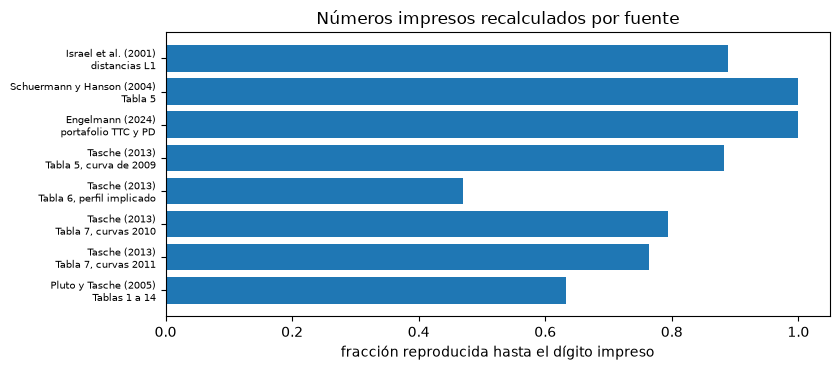

In [7]:
# Dibujar la fracción de números impresos reproducidos hasta el dígito impreso, por fuente
fig, ax = plt.subplots(figsize=(8.5, 3.8))
labels = [r[0].replace(", ", "\n", 1) for r in rows]
shares = [r[2] / r[1] for r in rows]
ax.barh(range(len(rows)), shares, color="tab:blue")
ax.set_yticks(range(len(rows)))
ax.set_yticklabels(labels, fontsize=7)
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel("fracción reproducida hasta el dígito impreso")
ax.set_title("Números impresos recalculados por fuente")
fig.tight_layout()
plt.show()

## Resultados

- **Lo que existe.** Los casos de calificaciones y calibración recalculan 413 números impresos de cinco artículos junto a sus impresos, y el motor reproduce 296 de ellos hasta el dígito impreso. Por fuente: Israel et al., 8 de 9 distancias (mayor diferencia 0,0004 en la distancia L1); la Tabla 5 de Schuermann y Hanson, 18 de 18 valores (las seis filas coinciden bajo la regla de media unidad del último dígito); Engelmann, 12 de 12 números (un cuarto portafolio se verifica dentro del redondeo de sus entradas impresas y no está en la cuenta); la Tabla 5 de Tasche, 15 de 17 (mayor diferencia 0,0010 puntos), la Tabla 6, 8 de 17 (0,0013) y las curvas de la Tabla 7, 54 de 68 en 2010 y 52 de 68 en 2011 (mayor 0,0005 y 0,0004 puntos); Pluto y Tasche, 129 de 204 (mayor 0,10 puntos).
- **Las diferencias están registradas y explicadas.** La única distancia de Israel et al. que no coincide imprime 0,1169 donde la matriz da 0,1165, y es igual a 0,1169 desde el generador impreso del artículo. Los valores p impresos de Tasche (4,6, 8,0, 4,0 y 11,3% en 2010; 78,5, 89,4, 36,6 y 82,2% en 2011) quedan a menos de 0,36 puntos de los del artefacto, de 100.000 simulaciones frente a las 2.000 del artículo. De las 204 celdas de Pluto y Tasche, 60 difieren en una unidad del último dígito y 15 en más (0,02 a 0,10 puntos), listadas arriba: la Tabla 11 al 75% y al 95%, la Tabla 12 para B al 99,9% y las tablas de varios períodos 13 y 14, cuyo impreso queda sobre el Monte Carlo del motor.
- **Recálculos independientes.** En una grilla de 36 casos los valores p de Jeffreys del motor igualan la función de distribución Beta calculada como cuadratura de su densidad (mayor diferencia 5,5e-12) y sus valores p binomiales igualan la suma racional exacta de los términos binomiales (5,6e-16): 72 de 72 dentro de 1e-9. Se descarta la comparación con las llamadas propias de SciPy, porque el motor hace esas llamadas y la diferencia solo podía ser 0.
- **Leído en otro cuaderno o no vuelto a correr aquí.** La exposición de Hull-White contra ORE se demuestra en el cuaderno 08 del tema de contraparte y se lee allá. La igualdad del estimador de cohorte con `transitionMatrix` es un test del motor (RV-415) que este cuaderno no vuelve a correr, así que se informa y no se cuenta.
- **La afirmación.** Los cinco enunciados de BS-2 que este cuaderno puede leer se listan con sus valores.

Lo que este cuaderno no muestra: las reconciliaciones de los otros casos (los cuadernos de sus temas nombran sus referencias).

## Resumen

- Los casos de calificaciones y calibración contrastan el motor con cinco artículos impresos y con dos recálculos independientes de sus valores p, e informan cada diferencia: 296 de 413 números impresos hasta el dígito impreso, el resto con su celda y su explicación.
- Una diferencia explicada sigue listada; donde la aritmética de un artículo difiere de su texto el motor sigue el texto.
- Una verificación contra la misma llamada que hace el motor prueba solo la parametrización; los valores p se contrastan en cambio con una cuadratura y con una suma exacta.
- La reconciliación de Hull-White contra ORE se demuestra en el tema 08; la igualdad con `transitionMatrix` es un test del motor que este cuaderno informa y no vuelve a correr.
- La afirmación BS-2 cuenta lo que existe; no dice que cada número del motor esté reconciliado.

**Qué probar después.** Recalcula una tabla de Pluto y Tasche con otro nivel de confianza y compárala con lo impreso; luego lee los cuadernos del tema siguiente.

## Referencias

- Israel, R. B., Rosenthal, J. S. y Wei, J. Z. (2001), Finding generators for Markov chains via empirical transition matrices, with applications to credit ratings, Mathematical Finance 11(2). https://doi.org/10.1111/1467-9965.00114
- Schuermann, T. y Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190, Tabla 5. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Tasche, D. (2013), The art of probability-of-default curve calibration, Journal of Credit Risk 9(4), Tablas 5 a 9. https://doi.org/10.21314/jcr.2013.169
- Pluto, K. y Tasche, D. (2005), Estimating probabilities of default for low default portfolios, arXiv cond-mat/0411699, Tablas 1 a 14. https://arxiv.org/abs/cond-mat/0411699
- Engelmann, B. (2024), Spurious default probability projections in credit risk stress testing models, arXiv 2401.08892, sección 4.
- SciPy, `scipy.integrate.quad`, en la versión fijada de notebooks/requirements.txt, y los módulos `math` y `fractions` de la biblioteca estándar de Python.